# Amplitude Based FM Modulation and Demodulation
In this code, I employed an AM-demodulation-based approach for FM demodulation. Although
this method is straightforward, it relies on derivatives and multiple multiplications and filters ,
which makes it sensitive to high noise levels.  
Amirhossein Azizi

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.signal as sig
import scipy
from math import e, pi
from numpy.fft import fft, ifft, fftshift, ifftshift

In [54]:
plt.rcParams['figure.dpi'] = 150

In [55]:
def FT(x,fs):
    pi=math.pi
    n=2**nextpow2(len(x))
    X=fftshift(fft(x,n))
    f=np.arange(-fs/2,fs/2,fs/n)
    return f, X

In [56]:
def nextpow2(n):
    return int(np.ceil(np.log2(n)))

In [57]:
def flatfilterL(x, fs, w, fcut):
    N=2**nextpow2(len(x))
    f=np.arange(-fs/2,fs/2,fs/N)
    f_c=fcut-w
    c=f_c**2/math.log(math.sqrt(2))
    gp=e**(-f**2/c)
    H=np.zeros(N)
    i2=np.argmin(np.abs(f-w))
    i1=np.argmin(np.abs(f+w))
    H[i1:i2+1]=1
    ind_half=int(len(gp)/2);
    H[i2+1:len(H)]=gp[ind_half+1 :ind_half+1+len(H)-i2-1]
    H[i1-1::-1]=gp[ind_half:ind_half-i1:-1]
    X=fftshift(fft(x,N))
    Y=X*H
    return np.real(ifft(ifftshift(Y)))

In [58]:
def flatfilterB(x, fs, w, dev_3dB, fcenter):
    N=2**nextpow2(len(x))
    f=np.arange(-fs/2,fs/2,fs/N)
    fcut_u=fcenter+w/2+dev_3dB#upper cuttoff frequency
    fcut_l=fcenter-w/2-dev_3dB;#lower cutoff frequency
    
    c=dev_3dB**2/math.log(math.sqrt(2))
    gp=e**(-f**2/c)
    
    H=np.zeros(N)
    
    ind_half=N//2
    f1=f[len(f)//2:len(f)]
    f2=f[0:len(f)//2]
    H1=np.zeros(N//2)
    H2=np.zeros(N//2)
    
    i1_u=np.argmin(np.abs(f1-fcenter-w/2))
    i1_l=np.argmin(np.abs(f1-fcenter+w/2))
    
    H1[i1_l:i1_u+1]=1;
    H1[i1_l-1::-1]=gp[N//2-1:N//2-1-(i1_l):-1]
    H1[i1_u+1:len(H1)]=gp[N//2:len(H)-(i1_u+1)]
    
    i2_u=np.argmin(np.abs(f2+fcenter+w//2))
    i2_l=np.argmin(np.abs(f2+fcenter-w//2))
    
    H2[i2_u:i2_l+1]=1;
    H2[i2_u-1::-1]=gp[N//2-1:N//2-1-i2_u:-1]
    
    H2[i2_l+1:len(H2)]=gp[N//2:len(H)-(i2_l+1)]
    H=np.concatenate((H2,H1))
    #part2
    X=fftshift(fft(x,N))
    Y=H*X
    return np.real(ifft(ifftshift(Y)))

In [59]:
def awgn(x, SNR):
    P_Sig=np.mean(np.abs(x)**2)
    Linear_SNR=10**(SNR/10)
    P_Noise=P_Sig/Linear_SNR
    Noise = np.sqrt(P_Noise)*np.random.randn(*x.shape)
    return x + Noise

In [60]:
#message signal definition

fs=32*2**nextpow2(1e4);#sampling Frequency
print(fs)

524288


In [61]:
t=np.arange(0,4,1/fs);#time

print(math.log2(len(t)))

m=sig.chirp(t,f0=0,f1=50,t1=4,method='linear')#a chirp signal as the

[f,M]=FT(m,fs)#fourier transform of the message signal

21.0


2097152 2097152


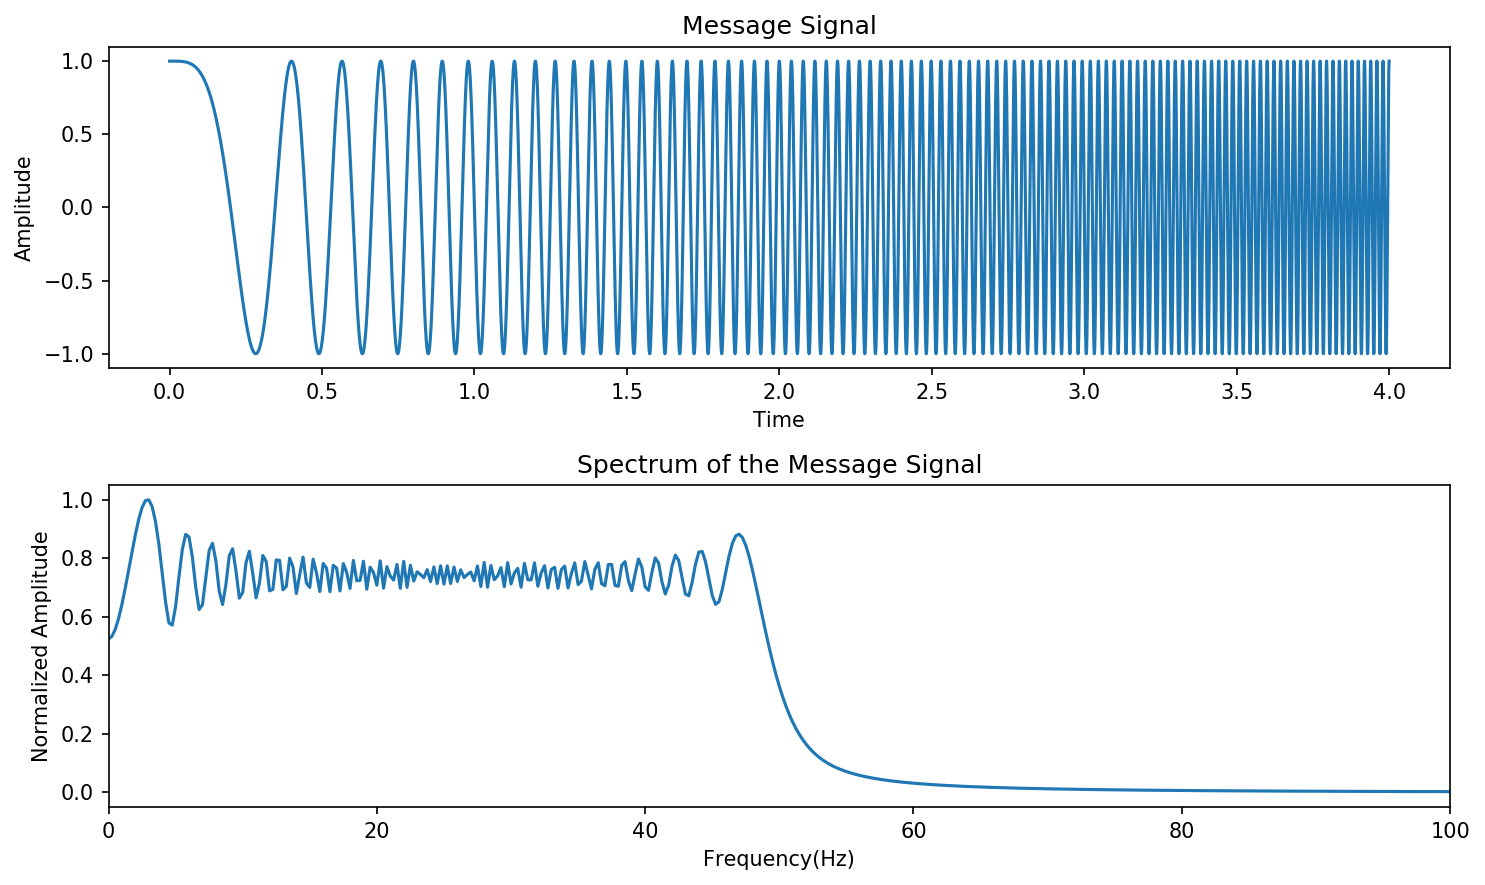

In [62]:
#ploting the message signal and its spectrum

plt.figure(figsize=(10, 6))

plt.subplot(2,1,1)

plt.plot(t,m)

plt.title('Message Signal')

plt.xlabel('Time')

plt.ylabel('Amplitude')

plt.subplot(2,1,2)

plt.plot(f,np.abs(M)/np.max(np.abs(M)))

plt.title('Spectrum of the Message Signal')

plt.xlabel('Frequency(Hz)')

plt.ylabel('Normalized Amplitude')

plt.xlim(0,100)

plt.tight_layout()

print(len(f),len(M))

In [63]:
#Modulation

Ac=100;#Amplitude of the carrier

fc=1e4;# frequency of the carrier signal

kf=150;#frequency deviation

from scipy.integrate import cumtrapz

cumint_m=cumtrapz(m, t, initial=0) #cumulative integral of the message signal

u=Ac*np.cos(2*pi*fc*t+2*pi*kf*cumint_m)#Modulated Signal

[f,U]=FT(u,fs)#Fourier Transform of the Modulated Signal

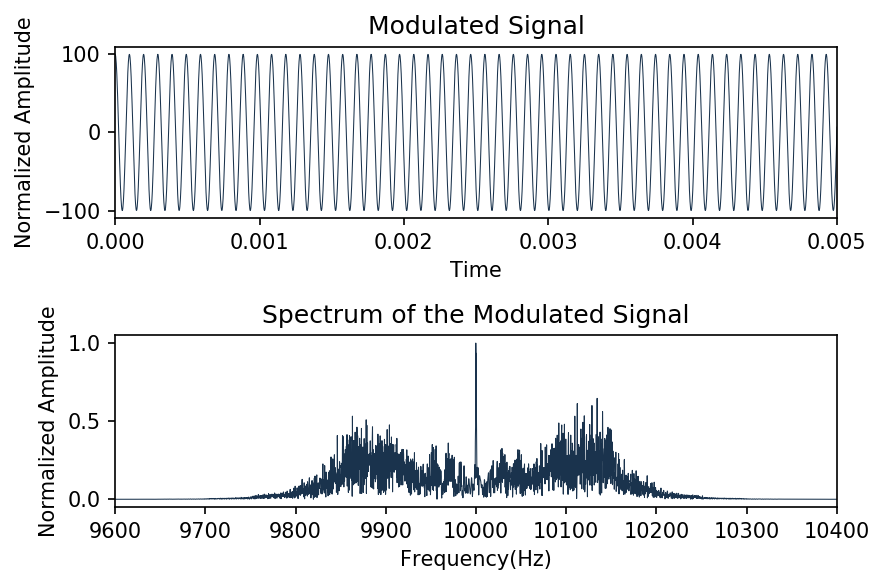

In [64]:
plt.figure()

plt.subplot(2,1,1)

plt.plot(t,u,linewidth=0.5, color=(0.1, 0.2, 0.3))

plt.xlim(0,0.5*1e-2)

plt.title('Modulated Signal')

plt.xlabel('Time')

plt.ylabel('Normalized Amplitude')

plt.subplot(2,1,2)

plt.plot(f,np.abs(U)/np.max(np.abs(U)), linewidth=0.5, color=(0.1, 0.2, 0.3))

plt.title('Spectrum of the Modulated Signal')

plt.xlabel('Frequency(Hz)')

plt.ylabel('Normalized Amplitude')

plt.xlim(9600,10400)

plt.tight_layout()

C:\ProgramData\Anaconda3\lib\site-packages\mkl_fft\_numpy_fft.py:331: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  output = mkl_fft.rfft_numpy(a, n=n, axis=axis)


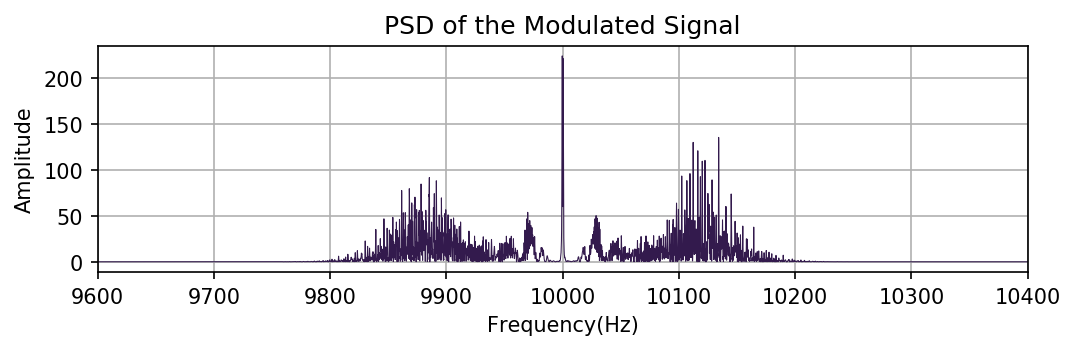

In [65]:
#Periodgram of the Modulated Signal

n=4*2**nextpow2(len(u))

#w=np.ones(n)

w=sig.windows.hamming(len(u))

[f, Pxx]=sig.periodogram(u, fs=fs, window=w, nfft=n, scaling='density')

plt.figure(figsize=(8,2))

plt.plot(f,Pxx,linewidth=0.5,color=(0.2,0.1,0.3))

plt.title('PSD of the Modulated Signal')

plt.ylabel('Amplitude')

plt.xlabel('Frequency(Hz)')

plt.xlim(9600,10400)

plt.grid()

In [66]:
#spectrogram of the Modulated Signal

n_w=256;

w_s=sig.windows.hamming(n_w);

n_ov=128;

n_fft=2048;

f_sp,t_sp,S=sig.spectrogram(u, fs=fs, nperseg=n_w, noverlap=n_ov, window=w_s,nfft=n_fft ,scaling='density')

C:\ProgramData\Anaconda3\lib\site-packages\mkl_fft\_numpy_fft.py:331: FutureWarning: Using a non-tuple sequence for multidimensional indexing is deprecated; use `arr[tuple(seq)]` instead of `arr[seq]`. In the future this will be interpreted as an array index, `arr[np.array(seq)]`, which will result either in an error or a different result.
  output = mkl_fft.rfft_numpy(a, n=n, axis=axis)


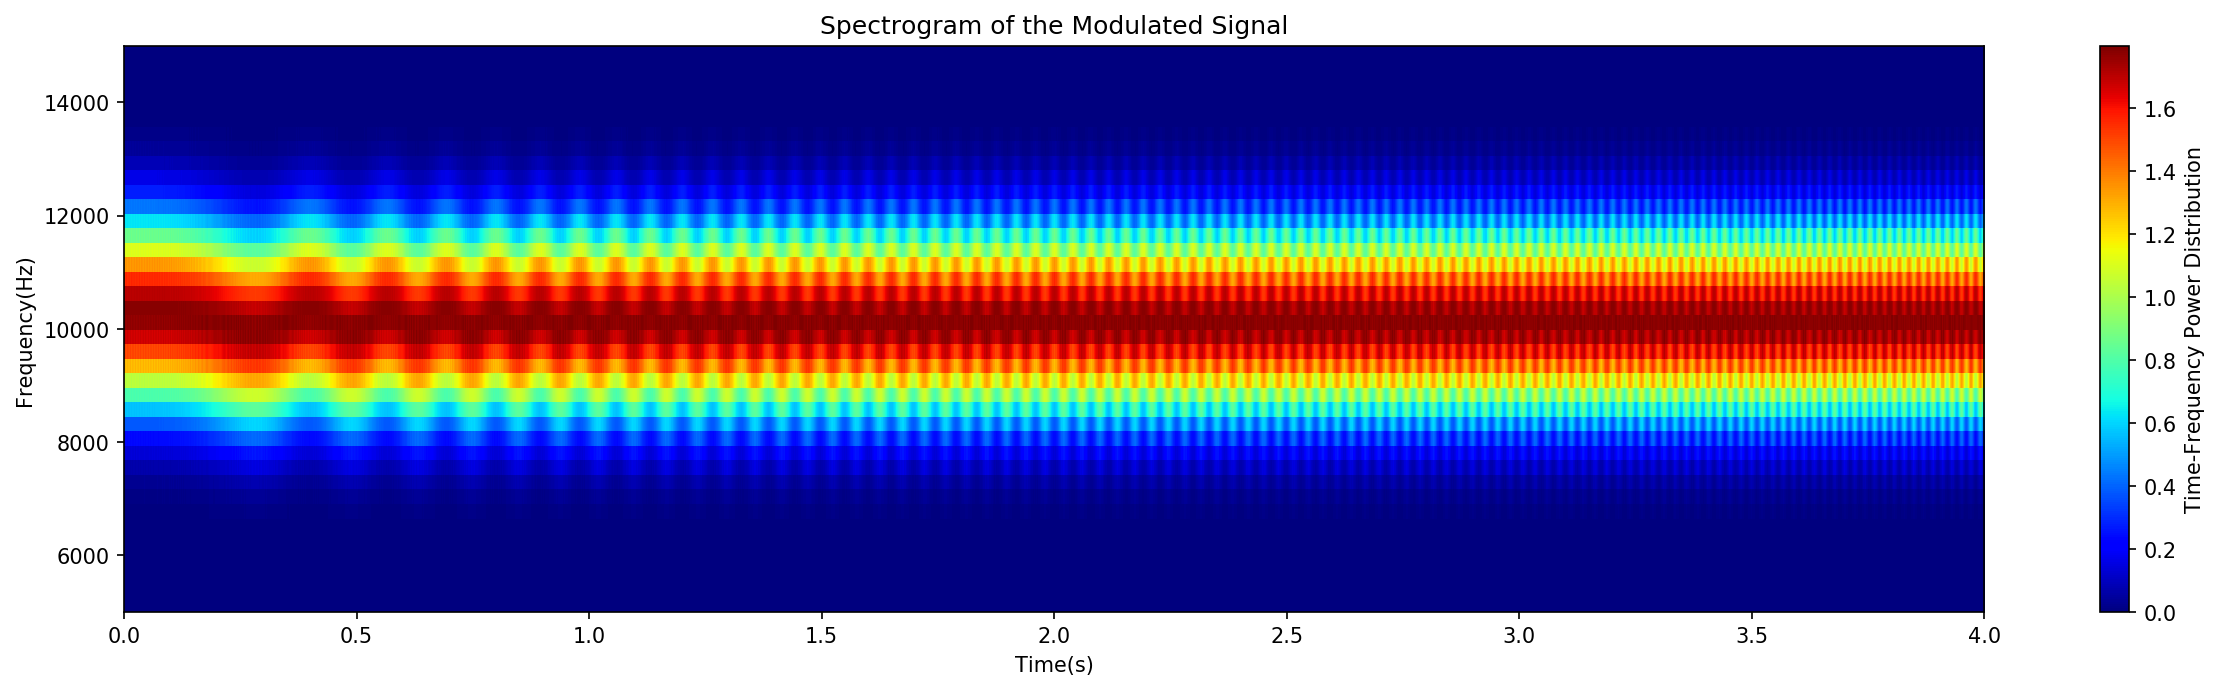

In [67]:
plt.figure(figsize=[20,5])

plt.imshow(S,extent=[t_sp.min(),t_sp.max(),f_sp.min(),f_sp.max()],origin='lower',
           cmap='jet',vmin=np.min(S),vmax=np.max(S),aspect='auto')

plt.colorbar(label='Time-Frequency Power Distribution')

plt.title('Spectrogram of the Modulated Signal')

plt.xlabel('Time(s)')

plt.ylabel('Frequency(Hz)')

plt.ylim(5e3,15e3)

plt.show()

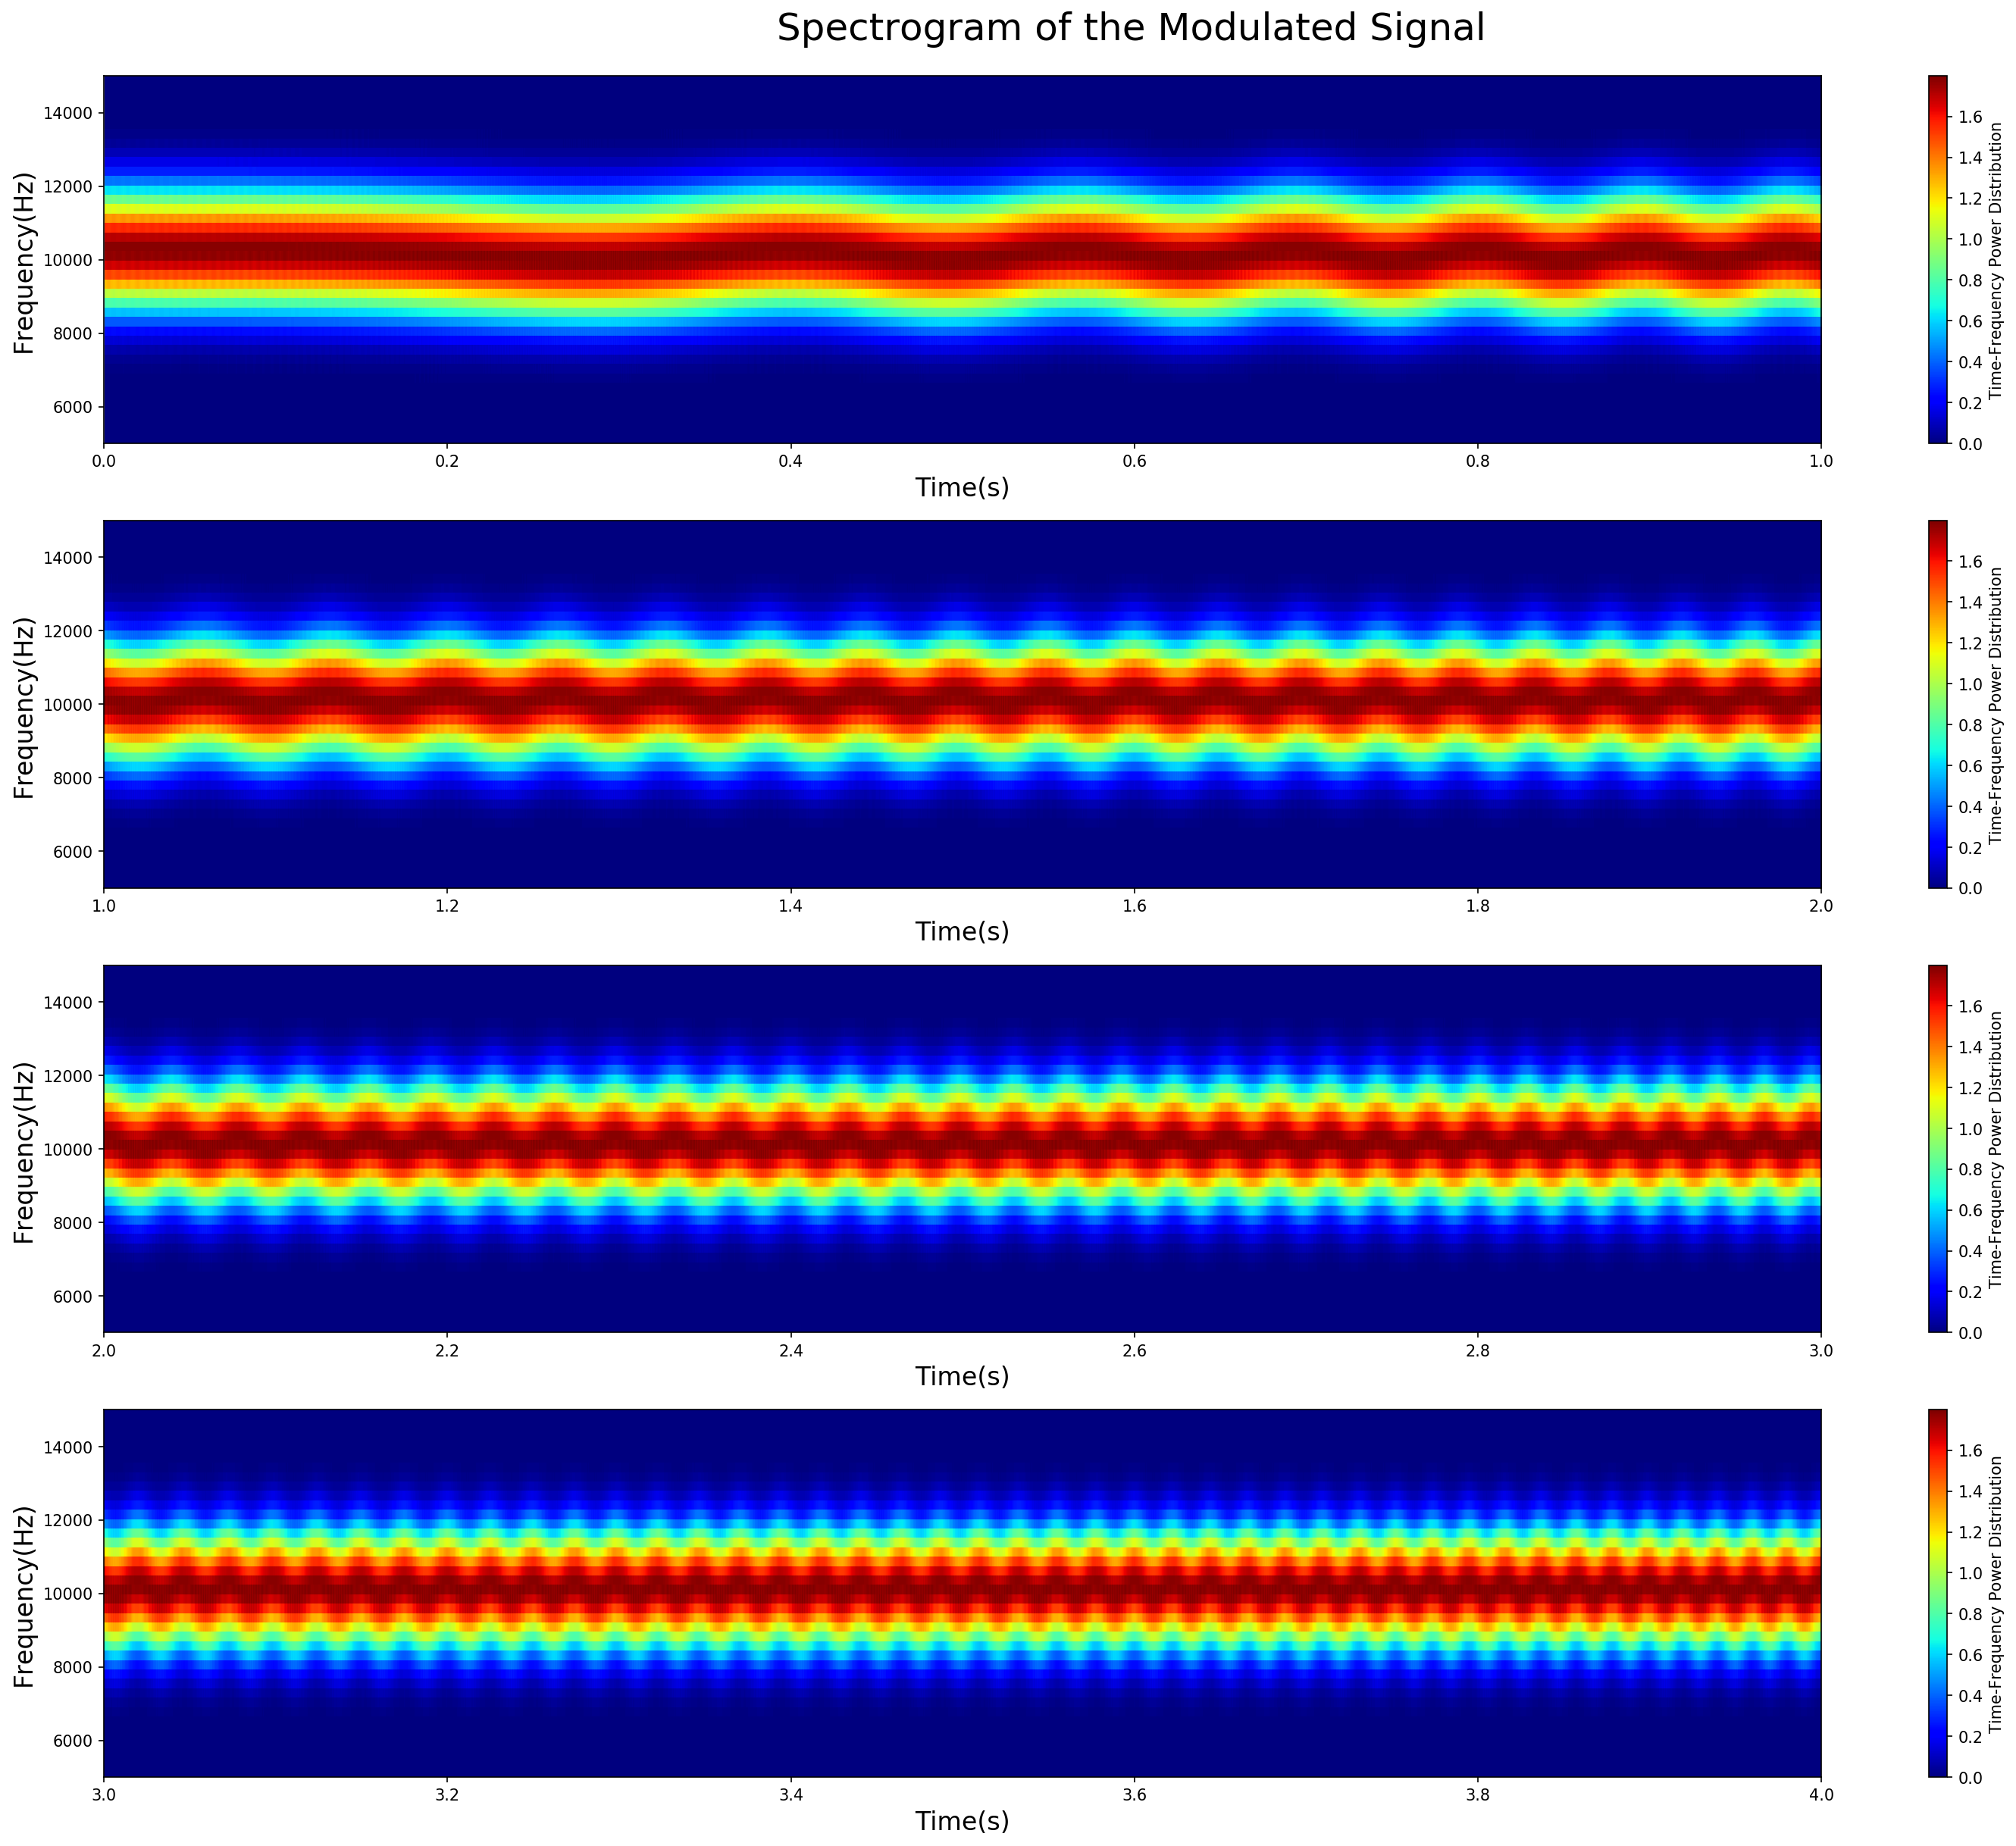

In [68]:
plt.figure(figsize=[20,20])

for i in range(4):
    plt.subplot(5,1,i+1)
    plt.imshow(S,extent=[t_sp.min(),t_sp.max(),f_sp.min(),f_sp.max()],
               origin='lower',cmap='jet',vmin=np.min(S),vmax=np.max(S),aspect='auto')

    plt.colorbar(label='Time-Frequency Power Distribution')

    plt.xlabel('Time(s)',fontsize=16)

    plt.ylabel('Frequency(Hz)',fontsize=16)

    plt.ylim(5e3,15e3)

    plt.xlim(i,i+1)

    plt.suptitle('Spectrogram of the Modulated Signal',fontsize=24)

plt.tight_layout(rect=[0, 0, 1, 0.96])
#rect = [left, bottom, right, top]

In [69]:
#Pass the Signal Through the AWGN Channel
r=awgn(u,30)

In [70]:
#Demodulation
r_H=(1/2*pi)*np.imag(sig.hilbert(r));#Hilbert Trandform of the Modalted Signal

y=np.gradient(r_H,t);#derivative of the Scaled Hilbert Transform of the Modulated Signal

y1=y-fc*u;

y2=2*np.cos(2*pi*fc*t)*y1;

y3=flatfilterB(y2,fs,500,100,2*fc);

y4=2*u*y3;

y5=flatfilterB(y4,fs,500,100,fc);

y6=y5*np.cos(2*pi*fc*t);

y7=flatfilterL(y6,fs,250,50);

y7=y7-np.mean(y7);

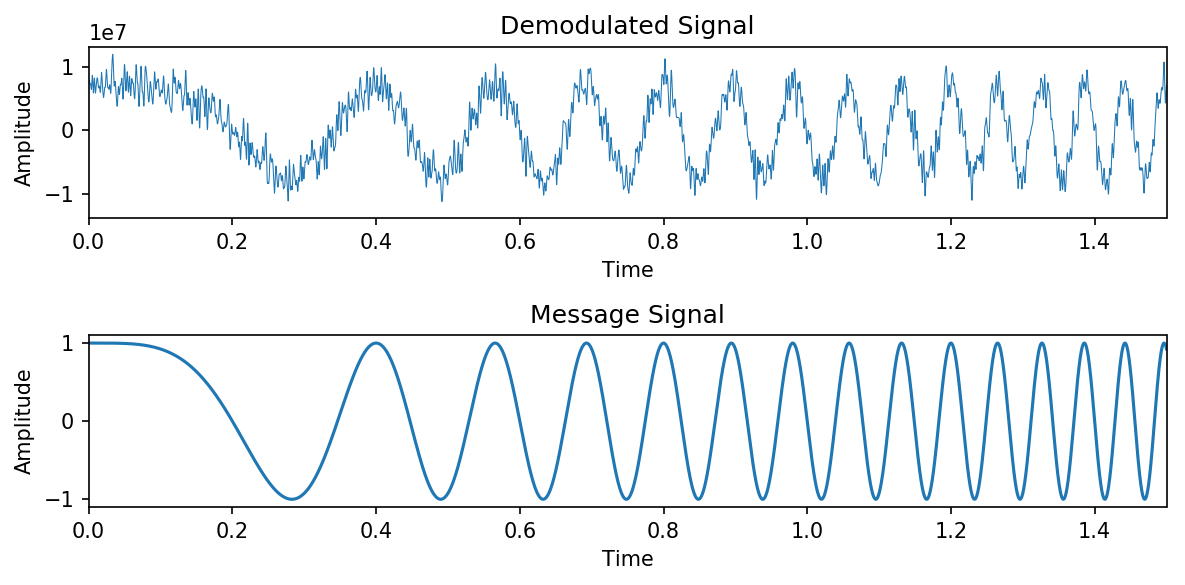

In [71]:
#plot the Demodulated Signal versus Oroginal Message Siganl

plt.figure(figsize=[8,4])

plt.subplot(2,1,1)

plt.plot(t,y7,linewidth=0.5)#/np.max(np.abs(y7)))

plt.xlim(0,1.5)

plt.title('Demodulated Signal')

plt.xlabel('Time')

plt.ylabel('Amplitude')

plt.subplot(2,1,2)

plt.plot(t,m)

plt.title('Message Signal')

plt.xlabel('Time')

plt.ylabel('Amplitude')

plt.xlim(0,1.5)

plt.tight_layout()

